# 04 — Exploratory Data Analysis

**Milestone 2 · Tasks 4 & 5:** explore how goal, duration, category,
subcategory, location, updates and reward levels relate to success; create
visualisations and summary statistics; document findings that feed the
machine-learning phase.

All analysis runs on the **training split only**. Looking at test-set
relationships and then choosing features based on what you saw is leakage
by way of the analyst's memory.

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 50)

mpl.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})
TEAL, PLUM, CORAL, SAND = "#2E7D6F", "#7B5EA7", "#C0392B", "#D9A455"
FIG = Path("../reports/figures")

train = pd.read_parquet("../data/train_featured.parquet")
test = pd.read_parquet("../data/test_featured.parquet")
print(f"Train {train.shape[0]:,} | Test {test.shape[0]:,}")

BASE_RATE = train["success"].mean()
print(f"Overall success rate (train): {BASE_RATE:.2%}")
print(f"Majority-class accuracy baseline: {max(BASE_RATE, 1 - BASE_RATE):.2%}")

Train 30,702 | Test 7,676
Overall success rate (train): 54.74%
Majority-class accuracy baseline: 54.74%


That baseline number is the one to keep in mind throughout. Any claim that
a factor "predicts success" has to beat 54.8%, and the 80% target in the
brief represents about 25 points of real lift.

In [2]:
def success_by(frame, col, min_n=30):
    """Success rate by group, with a Wald 95% interval and group size."""
    g = frame.groupby(col, observed=True)["success"].agg(["mean", "size"])
    g = g[g["size"] >= min_n].copy()
    se = np.sqrt(g["mean"] * (1 - g["mean"]) / g["size"])
    g["ci95"] = 1.96 * se
    g["lift_vs_base"] = g["mean"] - BASE_RATE
    return g.rename(columns={"mean": "success_rate", "size": "n"})


def barh_rates(g, title, fname, color=TEAL, figsize=(8, 5)):
    g = g.sort_values("success_rate")
    fig, ax = plt.subplots(figsize=figsize)
    ax.barh(range(len(g)), g["success_rate"], xerr=g["ci95"],
            color=color, error_kw={"ecolor": "#555", "lw": 1})
    ax.axvline(BASE_RATE, color=CORAL, ls="--", lw=1.4,
               label=f"overall {BASE_RATE:.1%}")
    ax.set_yticks(range(len(g)))
    ax.set_yticklabels([f"{i}  (n={int(n):,})" for i, n in zip(g.index, g["n"])],
                       fontsize=8)
    ax.set_xlabel("Success rate")
    ax.set_title(title)
    ax.legend(fontsize=8, loc="lower right")
    plt.tight_layout()
    plt.savefig(FIG / fname, dpi=130, bbox_inches="tight")
    plt.show()

## 4.1 Goal — the strongest launch-time signal

In [3]:
train["goal_decile"] = pd.qcut(train["goal"], 10, duplicates="drop")
goal_tbl = success_by(train, "goal_decile")
goal_tbl["median_goal"] = train.groupby("goal_decile", observed=True)["goal"].median()
goal_tbl[["median_goal", "n", "success_rate", "ci95"]].round(4)

,median_goal,n,success_rate,ci95
goal_decile,,,,
"(0.999, 750.0]",500.0,3184,0.7120,0.0157
"(750.0, 1250.0]",1000.0,3002,0.6682,0.0168
"(1250.0, 2000.0]",1800.0,3673,0.6662,0.0153
"(2000.0, 3000.0]",2700.0,3989,0.6247,0.0150
"(3000.0, 4000.0]",3600.0,2262,0.5902,0.0203
"(4000.0, 5000.0]",5000.0,3385,0.5134,0.0168
"(5000.0, 7000.0]",6000.0,2057,0.5241,0.0216
"(7000.0, 10000.0]",10000.0,3692,0.4691,0.0161
"(10000.0, 20000.0]",15000.0,3042,0.3820,0.0173


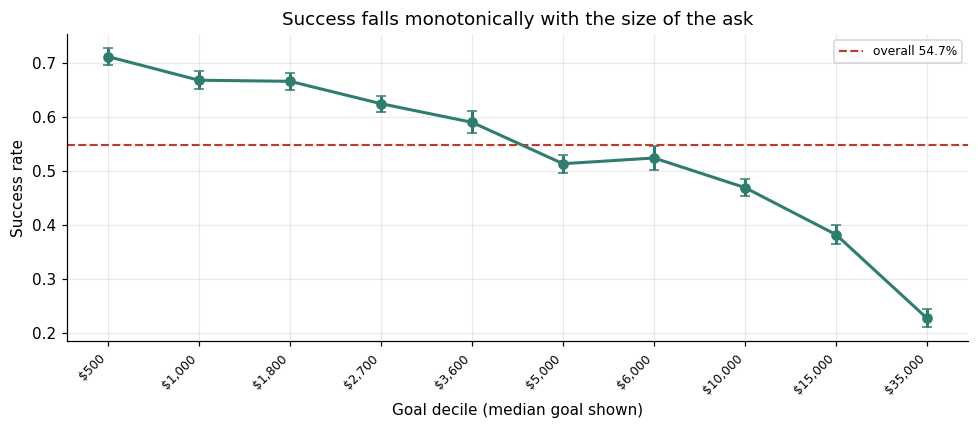

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(goal_tbl))
ax.errorbar(x, goal_tbl["success_rate"], yerr=goal_tbl["ci95"],
            marker="o", color=TEAL, lw=2, capsize=3)
ax.axhline(BASE_RATE, color=CORAL, ls="--", lw=1.4, label=f"overall {BASE_RATE:.1%}")
ax.set_xticks(x)
ax.set_xticklabels([f"${v:,.0f}" for v in goal_tbl["median_goal"]],
                   rotation=45, ha="right", fontsize=8)
ax.set_xlabel("Goal decile (median goal shown)")
ax.set_ylabel("Success rate")
ax.set_title("Success falls monotonically with the size of the ask")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "success_by_goal_decile.png", dpi=130, bbox_inches="tight")
plt.show()

In [5]:
lo, hi = goal_tbl["success_rate"].iloc[0], goal_tbl["success_rate"].iloc[-1]
print(f"Lowest goal decile:  {lo:.1%} success")
print(f"Highest goal decile: {hi:.1%} success")
print(f"Spread: {lo - hi:.1%} percentage points — and monotonic across all deciles.")

Lowest goal decile:  71.2% success
Highest goal decile: 22.7% success
Spread: 48.5% percentage points — and monotonic across all deciles.


This is the cleanest relationship in the dataset and it is entirely
available at launch. Note the practical shape: the drop is steep at the low
end and flattens out above roughly $20k, which is exactly the shape that
makes goal-setting advice actionable for a recommendation engine.

## 4.2 Category and subcategory

In [6]:
cat_tbl = success_by(train, "category")
cat_tbl[["n", "success_rate", "ci95", "lift_vs_base"]].sort_values(
    "success_rate", ascending=False).round(4)

,n,success_rate,ci95,lift_vs_base
category,,,,
Dance,502,0.7669,0.0370,0.2196
Theater,1776,0.7061,0.0212,0.1587
Music,7632,0.6762,0.0105,0.1289
Art,2565,0.5653,0.0192,0.0179
Comics,723,0.5422,0.0363,-0.0052
Food,988,0.5091,0.0312,-0.0382
Film & Video,9065,0.5084,0.0103,-0.0389
Design,1173,0.4655,0.0285,-0.0819
Photography,886,0.4345,0.0326,-0.1128


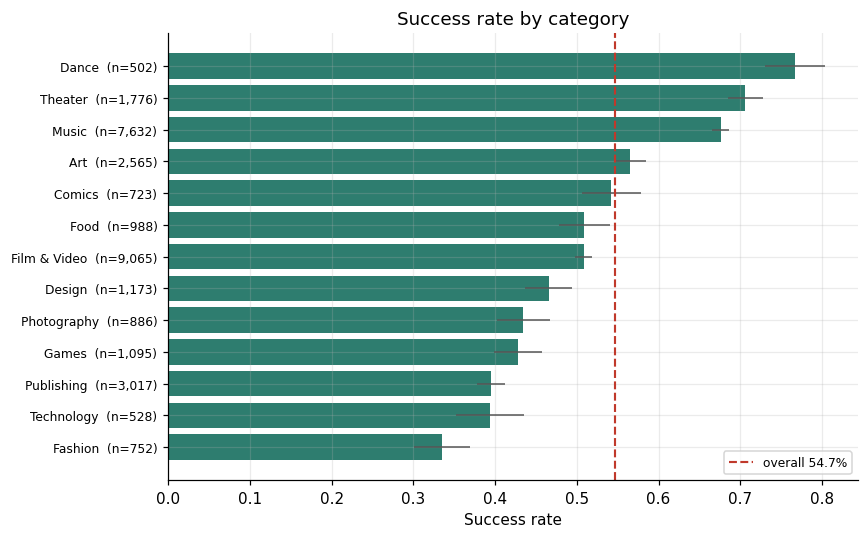

In [7]:
barh_rates(cat_tbl, "Success rate by category", "success_by_category.png", TEAL)

### The confound: category or goal?

Dance and Theater look excellent. But cheap-to-produce categories also ask
for less money, and we just established that small asks succeed. So is this
a category effect or a goal effect wearing a category costume?

In [8]:
cat_goals = train.groupby("category", observed=True).agg(
    median_goal=("goal", "median"),
    success_rate=("success", "mean"),
    n=("success", "size"),
).sort_values("median_goal")
cat_goals.round(3)

,median_goal,success_rate,n
category,,,
Dance,2500.000,0.767,502
Theater,2561.500,0.706,1776
Art,2600.000,0.565,2565
Comics,3000.000,0.542,723
Music,3000.000,0.676,7632
Photography,3000.000,0.435,886
Publishing,3800.000,0.395,3017
Fashion,4899.995,0.335,752
Film & Video,5000.000,0.508,9065


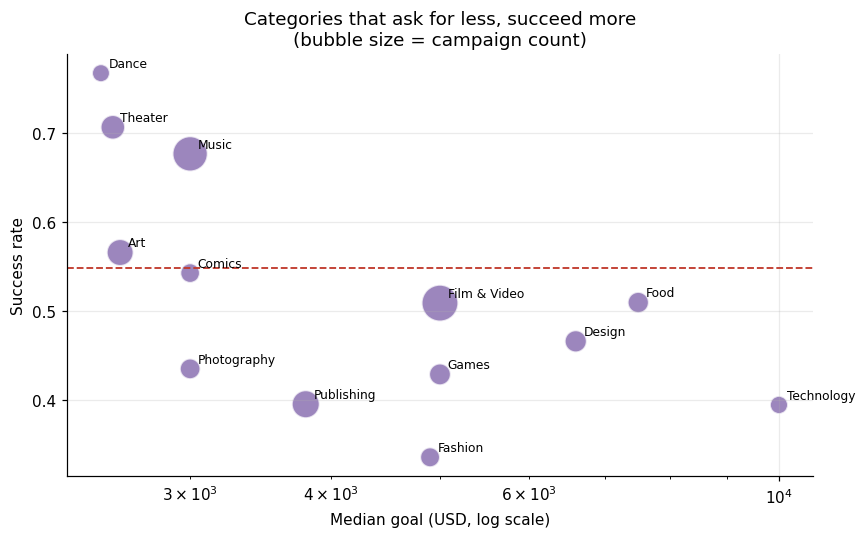

Spearman correlation, median goal vs success rate across categories: -0.683


In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(cat_goals["median_goal"], cat_goals["success_rate"],
           s=np.sqrt(cat_goals["n"]) * 6, color=PLUM, alpha=0.75,
           edgecolor="white", lw=1.2)
for name, r in cat_goals.iterrows():
    ax.annotate(name, (r["median_goal"], r["success_rate"]),
                fontsize=8, xytext=(5, 4), textcoords="offset points")
ax.set_xscale("log")
ax.axhline(BASE_RATE, color=CORAL, ls="--", lw=1.2)
ax.set_xlabel("Median goal (USD, log scale)")
ax.set_ylabel("Success rate")
ax.set_title("Categories that ask for less, succeed more\n(bubble size = campaign count)")
plt.tight_layout()
plt.savefig(FIG / "category_goal_confound.png", dpi=130, bbox_inches="tight")
plt.show()

corr = cat_goals["median_goal"].corr(cat_goals["success_rate"], method="spearman")
print(f"Spearman correlation, median goal vs success rate across categories: {corr:.3f}")

Strongly negative. So control for it: compare categories *within* goal
quartiles. If a category effect survives, it is real.

In [10]:
train["goal_quartile"] = pd.qcut(train["goal"], 4, labels=["Q1 (low)", "Q2", "Q3", "Q4 (high)"])
pivot = train.pivot_table(index="category", columns="goal_quartile",
                          values="success", aggfunc="mean", observed=True)
counts = train.pivot_table(index="category", columns="goal_quartile",
                           values="success", aggfunc="size", observed=True)
pivot = pivot.where(counts >= 25)
pivot.loc[pivot.mean(axis=1).sort_values(ascending=False).index].round(3)

goal_quartile,Q1 (low),Q2,Q3,Q4 (high)
category,,,,
Dance,0.813,0.792,0.725,0.433
Theater,0.817,0.755,0.624,0.427
Music,0.742,0.711,0.649,0.510
Food,0.708,0.677,0.508,0.398
Film & Video,0.676,0.596,0.514,0.347
Art,0.685,0.609,0.475,0.323
Comics,0.704,0.568,0.432,0.327
Design,0.651,0.547,0.422,0.364
Technology,0.649,0.529,0.415,0.291


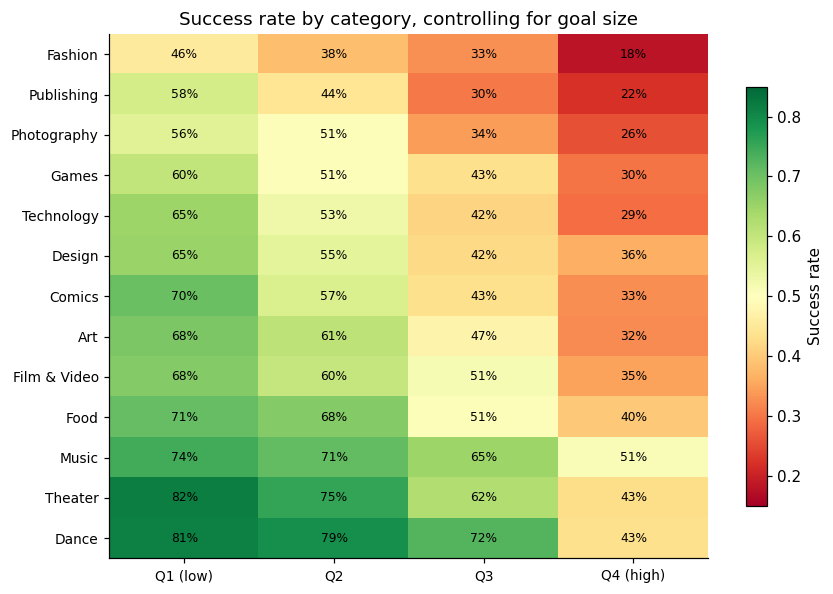

In [11]:
fig, ax = plt.subplots(figsize=(8, 5.5))
data = pivot.loc[pivot.mean(axis=1).sort_values().index]
im = ax.imshow(data.values, cmap="RdYlGn", vmin=0.15, vmax=0.85, aspect="auto")
ax.set_xticks(range(data.shape[1])); ax.set_xticklabels(data.columns, fontsize=9)
ax.set_yticks(range(data.shape[0])); ax.set_yticklabels(data.index, fontsize=9)
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        v = data.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8)
ax.set_title("Success rate by category, controlling for goal size")
ax.grid(False)
plt.colorbar(im, ax=ax, label="Success rate", shrink=0.8)
plt.tight_layout()
plt.savefig(FIG / "category_by_goal_quartile.png", dpi=130, bbox_inches="tight")
plt.show()

Read the rows, not the columns. Within *every* goal quartile the ordering
of categories is broadly preserved — so there is a genuine category effect
on top of the goal effect. Both belong in the model, and neither explains
the other away.

In [12]:
sub_tbl = success_by(train, "subcategory", min_n=80)
print("Top 8 subcategories:")
print(sub_tbl.nlargest(8, "success_rate")[["n", "success_rate", "ci95"]].round(3).to_string())
print("\nBottom 8 subcategories:")
print(sub_tbl.nsmallest(8, "success_rate")[["n", "success_rate", "ci95"]].round(3).to_string())

Top 8 subcategories:
                    n  success_rate   ci95
subcategory                               
Dance             502         0.767  0.037
Indie Rock       1360         0.756  0.023
Country & Folk    756         0.749  0.031
Classical Music   319         0.727  0.049
Jazz              302         0.715  0.051
Theater          1776         0.706  0.021
Rock             1270         0.680  0.026
Public Art        368         0.663  0.048

Bottom 8 subcategories:
                   n  success_rate   ci95
subcategory                              
Open Software    163         0.288  0.070
Video Games      549         0.293  0.038
Children's Book  406         0.325  0.046
Fashion          752         0.335  0.034
Technology       235         0.349  0.061
Nonfiction       637         0.361  0.037
Fiction          703         0.363  0.036
Hip-Hop          333         0.381  0.052


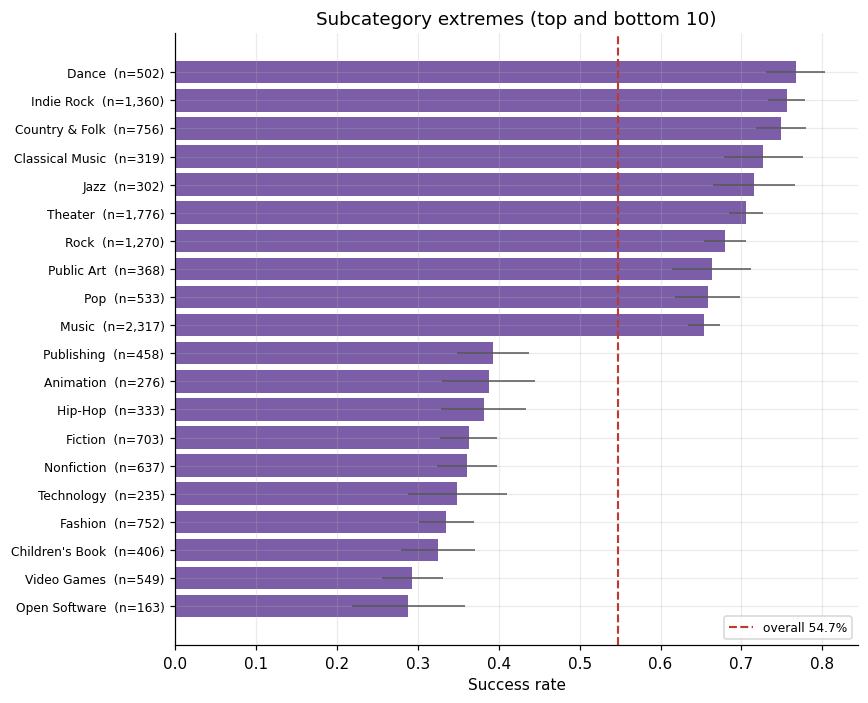

In [13]:
extremes = pd.concat([sub_tbl.nlargest(10, "success_rate"),
                      sub_tbl.nsmallest(10, "success_rate")])
barh_rates(extremes, "Subcategory extremes (top and bottom 10)",
           "success_by_subcategory.png", PLUM, figsize=(8, 6.5))

Subcategory spreads much wider than category — which is what makes it the
more valuable feature of the two despite the higher cardinality.

## 4.3 Duration — shorter is better

In [14]:
dur_tbl = success_by(train, "duration_bucket")
dur_tbl[["n", "success_rate", "ci95", "lift_vs_base"]].round(4)

,n,success_rate,ci95,lift_vs_base
duration_bucket,,,,
<=20d,2124,0.6780,0.0199,0.1306
21-30d,11079,0.5650,0.0092,0.0177
31-45d,8755,0.5860,0.0103,0.0386
46-60d,5327,0.4731,0.0134,-0.0743
>60d,3417,0.4258,0.0166,-0.1215


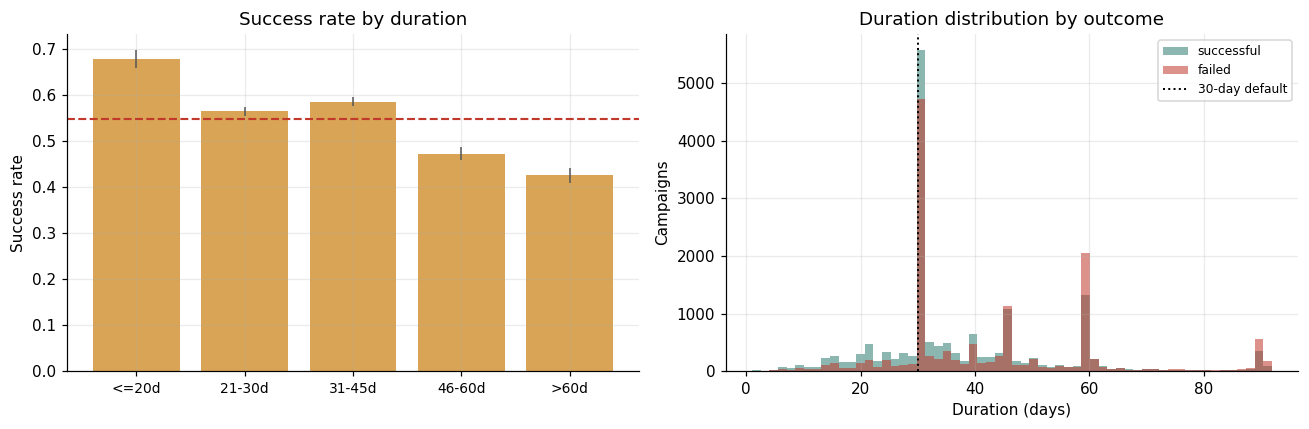

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
d = dur_tbl.reset_index()
axes[0].bar(range(len(d)), d["success_rate"], yerr=d["ci95"],
            color=SAND, error_kw={"ecolor": "#555", "lw": 1})
axes[0].axhline(BASE_RATE, color=CORAL, ls="--", lw=1.4)
axes[0].set_xticks(range(len(d)))
axes[0].set_xticklabels(d["duration_bucket"].astype(str), fontsize=9)
axes[0].set_ylabel("Success rate"); axes[0].set_title("Success rate by duration")

for label, sub, c in [("successful", train[train.success == 1], TEAL),
                      ("failed", train[train.success == 0], CORAL)]:
    axes[1].hist(sub["duration_days"], bins=60, alpha=0.55, label=label, color=c)
axes[1].axvline(30, color="black", ls=":", lw=1.3, label="30-day default")
axes[1].set_xlabel("Duration (days)"); axes[1].set_ylabel("Campaigns")
axes[1].set_title("Duration distribution by outcome"); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "success_by_duration.png", dpi=130, bbox_inches="tight")
plt.show()

In [16]:
print(f"Median duration, successful: {train.loc[train.success == 1, 'duration_days'].median():.1f} days")
print(f"Median duration, failed:     {train.loc[train.success == 0, 'duration_days'].median():.1f} days")
print(f"\n30-day campaigns:     {train['is_30_day'].mean():.1%} of all campaigns")
print(f"  success rate:       {train.loc[train.is_30_day == 1, 'success'].mean():.1%}")
print(f"  vs non-30-day:      {train.loc[train.is_30_day == 0, 'success'].mean():.1%}")

Median duration, successful: 31.0 days
Median duration, failed:     35.0 days

30-day campaigns:     30.3% of all campaigns
  success rate:       53.0%
  vs non-30-day:      55.5%


Counter-intuitive but consistent: **longer campaigns do worse**. A long
window signals low confidence, and momentum matters more than time on
Kickstarter. This is directly actionable advice for a recommendation
engine, and it is known at launch.

**Correction (Milestone 4 re-check):** the 30-day platform default does *not*
outperform. The output above shows 30-day campaigns succeeding **less** often
than the rest (about 53% against 55.5%), and notebook 10 (§11.6) shows they
also do worse than 26–29 day campaigns within every goal quartile. Campaigns
left at the default are a dip, not a sweet spot.

## 4.4 Reward levels and tier structure

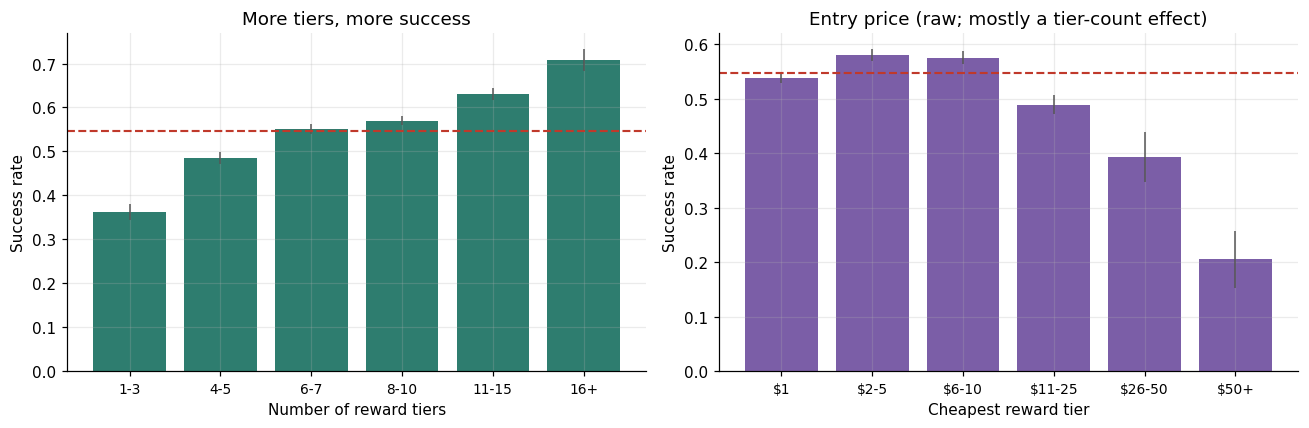

                n  success_rate
tier_bucket                    
1-3          2744         0.363
4-5          5148         0.485
6-7          7619         0.551
8-10         9194         0.570
11-15        4679         0.630
16+          1318         0.708

                     n  success_rate
min_tier_bucket                     
$1               11861         0.537
$2-5              8250         0.580
$6-10             6697         0.575
$11-25            3222         0.489
$26-50             443         0.393
$50+               229         0.205


In [17]:
train["tier_bucket"] = pd.cut(train["levels"], [0, 3, 5, 7, 10, 15, 100],
                              labels=["1-3", "4-5", "6-7", "8-10", "11-15", "16+"])
tier_tbl = success_by(train, "tier_bucket")

train["min_tier_bucket"] = pd.cut(train["min_tier"], [0, 1, 5, 10, 25, 50, 1e9],
                                  labels=["$1", "$2-5", "$6-10", "$11-25", "$26-50", "$50+"])
mintier_tbl = success_by(train, "min_tier_bucket")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, tbl, xlab, title, c in [
    (axes[0], tier_tbl, "Number of reward tiers", "More tiers, more success", TEAL),
    (axes[1], mintier_tbl, "Cheapest reward tier", "Entry price (raw; mostly a tier-count effect)", PLUM),
]:
    t = tbl.reset_index()
    ax.bar(range(len(t)), t["success_rate"], yerr=t["ci95"],
           color=c, error_kw={"ecolor": "#555", "lw": 1})
    ax.axhline(BASE_RATE, color=CORAL, ls="--", lw=1.4)
    ax.set_xticks(range(len(t))); ax.set_xticklabels(t.iloc[:, 0].astype(str), fontsize=9)
    ax.set_xlabel(xlab); ax.set_ylabel("Success rate"); ax.set_title(title)
plt.tight_layout()
plt.savefig(FIG / "success_by_reward_tiers.png", dpi=130, bbox_inches="tight")
plt.show()

print(tier_tbl[["n", "success_rate"]].round(3).to_string())
print()
print(mintier_tbl[["n", "success_rate"]].round(3).to_string())

**More tiers, more success** is real, and it is a launch-time decision the
creator fully controls — the most useful finding in this notebook from a
*recommendation* standpoint (Milestone 4).

**Correction (Milestone 4 re-check):** the entry-price pattern on the right
is mostly a *tier-count* effect. Campaigns with a high entry price also offer
far fewer tiers (a median of 3 against 8). Holding goal size and tier count
fixed, the raw gap of about −23 points shrinks to a few points (notebook 10,
§11.6), and adding a $10 tier to a campaign with a high entry price moves the
model's prediction by about 0.1 point. So the advice is *offer more tiers*,
not *add a $5 tier*.

## 4.5 Location

In [18]:
state_tbl = success_by(train, "state_raw", min_n=150)
print(f"States with >=150 campaigns: {len(state_tbl)}")
print("\nTop 8:"); print(state_tbl.nlargest(8, "success_rate")[["n", "success_rate", "ci95"]].round(3).to_string())
print("\nBottom 8:"); print(state_tbl.nsmallest(8, "success_rate")[["n", "success_rate", "ci95"]].round(3).to_string())

States with >=150 campaigns: 32

Top 8:
              n  success_rate   ci95
state_raw                           
NY         5310         0.648  0.013
MA          958         0.629  0.031
OR          941         0.614  0.031
IL         1373         0.610  0.026
MN          490         0.600  0.043
ME          199         0.593  0.068
WA         1013         0.584  0.030
DC          343         0.583  0.052

Bottom 8:
              n  success_rate   ci95
state_raw                           
FL         1123         0.375  0.028
NV          252         0.401  0.061
GA          769         0.430  0.035
NJ          440         0.441  0.046
AZ          448         0.449  0.046
IN          301         0.472  0.056
UT          307         0.476  0.056
NM          201         0.483  0.069


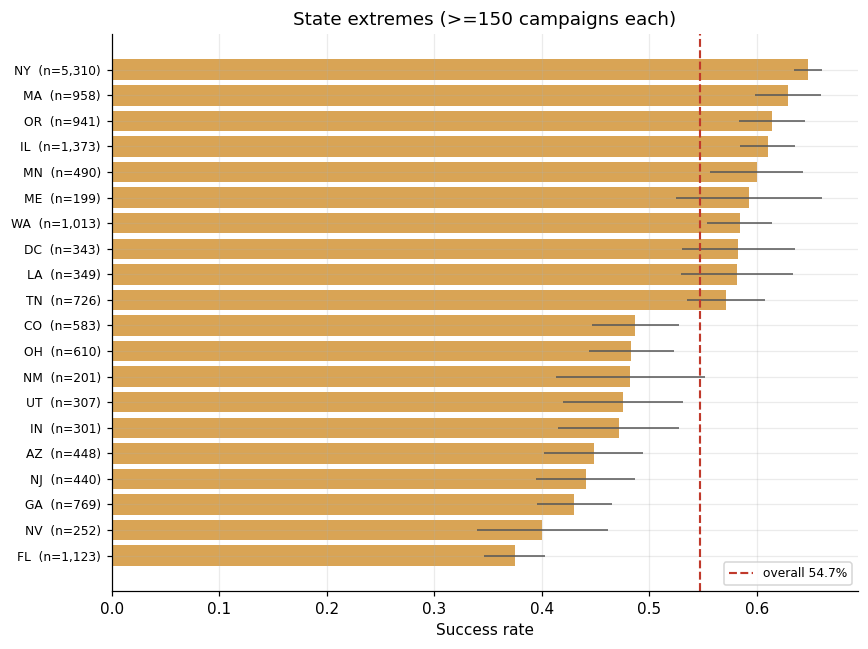

In [19]:
extremes = pd.concat([state_tbl.nlargest(10, "success_rate"),
                      state_tbl.nsmallest(10, "success_rate")])
barh_rates(extremes, "State extremes (>=150 campaigns each)",
           "success_by_state.png", SAND, figsize=(8, 6))

In [20]:
city_tbl = success_by(train, "city", min_n=120)
print(f"Cities with >=120 campaigns: {len(city_tbl)}")
print(city_tbl.sort_values("success_rate", ascending=False)[["n", "success_rate"]].round(3).to_string())

Cities with >=120 campaigns: 34
                    n  success_rate
city                               
Brooklyn         1217         0.723
Oakland           212         0.703
Austin            620         0.669
Portland          828         0.669
Philadelphia      452         0.657
Minneapolis       349         0.653
New York         2759         0.646
San Francisco     971         0.644
Chicago          1099         0.643
Boston            575         0.640
Seattle           675         0.631
Nashville         492         0.612
Lower East Side   120         0.608
Baltimore         211         0.602
Manhattan         223         0.601
New Orleans       230         0.600
Kansas City       135         0.593
Washington        347         0.585
Los Angeles      2867         0.555
Denver            277         0.549
Pittsburgh        211         0.545
Columbus          122         0.516
St Louis          141         0.496
Detroit           258         0.496
Salt Lake City    150         0.

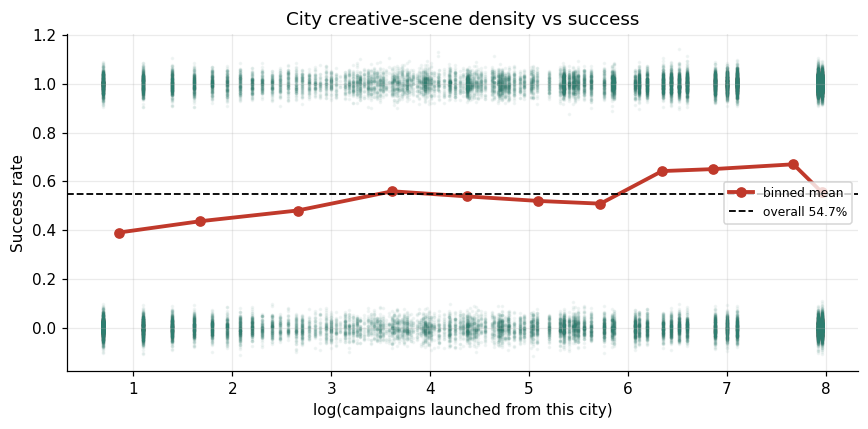

Spearman(log_city_project_count, success) = 0.1420


In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(train["log_city_project_count"], train["success"] + np.random.normal(0, 0.03, len(train)),
           s=2, alpha=0.05, color=TEAL)
bins = pd.qcut(train["log_city_project_count"], 12, duplicates="drop")
b = train.groupby(bins, observed=True).agg(x=("log_city_project_count", "mean"),
                                           y=("success", "mean"))
ax.plot(b["x"], b["y"], color=CORAL, lw=2.5, marker="o", label="binned mean")
ax.axhline(BASE_RATE, color="black", ls="--", lw=1.2, label=f"overall {BASE_RATE:.1%}")
ax.set_xlabel("log(campaigns launched from this city)")
ax.set_ylabel("Success rate")
ax.set_title("City creative-scene density vs success")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "city_density_vs_success.png", dpi=130, bbox_inches="tight")
plt.show()

print(f"Spearman(log_city_project_count, success) = "
      f"{train['log_city_project_count'].corr(train['success'], method='spearman'):.4f}")

**Correction (Milestone 4 re-check):** location is **not** a modest signal.
The tables above show success running from about 65% (New York) to about 37%
(Florida) across states with 150+ campaigns — a spread of roughly 27 points
that survives controlling for goal size. By city size, the smallest quartile
succeeds about 43% of the time against about 62% for the largest. A rank
correlation of 0.14 made the city signal look weak, but the success rates show
it is not: city density is among the top handful of inputs the final model
relies on (notebook 09).

## 4.6 `updates` — the central methodological problem

Now the important part. `updates` is by far the strongest single predictor
in this dataset. It is also **not available at launch**.

In [22]:
train["update_bucket"] = pd.cut(train["updates"], [-1, 0, 1, 3, 6, 12, 1000],
                                labels=["0", "1", "2-3", "4-6", "7-12", "13+"])
upd_tbl = success_by(train, "update_bucket")
upd_tbl[["n", "success_rate", "ci95", "lift_vs_base"]].round(4)

,n,success_rate,ci95,lift_vs_base
update_bucket,,,,
0,10194,0.2036,0.0078,-0.3437
1,3784,0.4355,0.0158,-0.1118
2-3,5021,0.6411,0.0133,0.0937
4-6,4868,0.7837,0.0116,0.2363
7-12,4232,0.8651,0.0103,0.3177
13+,2603,0.9166,0.0106,0.3693


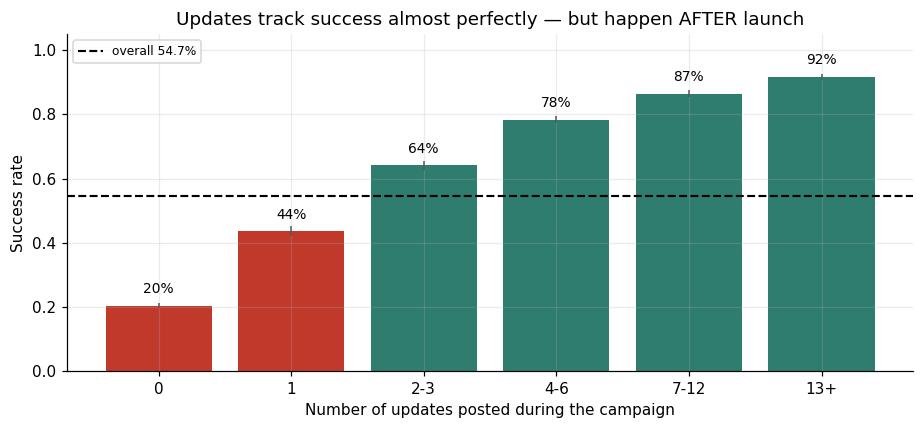

In [23]:
fig, ax = plt.subplots(figsize=(8.5, 4))
u = upd_tbl.reset_index()
bars = ax.bar(range(len(u)), u["success_rate"], yerr=u["ci95"],
              color=[CORAL if v < BASE_RATE else TEAL for v in u["success_rate"]],
              error_kw={"ecolor": "#555", "lw": 1})
ax.axhline(BASE_RATE, color="black", ls="--", lw=1.4, label=f"overall {BASE_RATE:.1%}")
ax.set_xticks(range(len(u))); ax.set_xticklabels(u["update_bucket"].astype(str))
ax.set_xlabel("Number of updates posted during the campaign")
ax.set_ylabel("Success rate")
ax.set_title("Updates track success almost perfectly — but happen AFTER launch")
ax.legend(fontsize=8)
for i, v in enumerate(u["success_rate"]):
    ax.text(i, v + 0.04, f"{v:.0%}", ha="center", fontsize=9)
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig(FIG / "updates_leakage.png", dpi=130, bbox_inches="tight")
plt.show()

From ~20% success at zero updates to ~92% at thirteen or more. No other
feature in the dataset comes close.

But consider what generates that number. A campaign that is visibly funding
well attracts a creator who keeps posting. A campaign that stalls goes
quiet. The causal arrow runs at least partly **backwards** — success causes
updates, not only the reverse. And by construction, none of it exists at
the moment a creator needs the prediction.

**Implication for Milestone 3.** `updates` cannot be used in a model that
predicts from launch-time information. It should be excluded from the
primary feature set before any model is trained, and the decision recorded
in the leakage register. The published benchmark for this dataset (80.2%
accuracy, F1 0.834) was produced with `updates` included, so our pre-launch
results will not be directly comparable to it — that comparison belongs in
Milestone 3, not here.

## 4.7 Which launch-time features carry the most signal

Ranking features *before* any model is fitted, so the ranking reflects the
data rather than one algorithm's inductive bias.

Two measures, because the feature types need different treatment:

- **Numeric** — absolute Spearman correlation with the target. Rank-based,
  so it is unaffected by the heavy skew in `goal`.
- **Categorical** — the success-rate spread between the best and worst
  levels that have at least 100 campaigns, which is how much outcome
  variation the feature separates.

In [24]:
NUMERIC = ["log_goal", "duration_days", "levels", "n_tiers_parsed",
           "log_min_tier", "log_max_tier", "median_tier", "tier_spread",
           "min_tier_pct_of_goal", "log_goal_per_day", "log_goal_per_tier",
           "launch_year", "launch_month", "launch_dow", "name_length",
           "name_word_count", "name_upper_ratio", "log_city_project_count",
           "log_goal_vs_subcat_median"]
CATEGORICAL = ["category", "subcategory", "state_raw"]

rows = []
for col in NUMERIC:
    rho = train[col].corr(train["success"], method="spearman")
    rows.append({"feature": col, "kind": "numeric",
                 "signal": abs(rho), "detail": f"Spearman {rho:+.3f}"})

for col in CATEGORICAL:
    g = success_by(train, col, min_n=100)["success_rate"]
    rows.append({"feature": col, "kind": "categorical",
                 "signal": g.max() - g.min(),
                 "detail": f"{g.min():.0%} to {g.max():.0%} across "
                           f"{len(g)} levels"})

signal = pd.DataFrame(rows).sort_values("signal", ascending=False)
signal.head(15).round(3).to_string(index=False)

'                  feature        kind  signal                      detail\n              subcategory categorical   0.479 29% to 77% across 48 levels\n                 category categorical   0.432 34% to 77% across 13 levels\n                state_raw categorical   0.348 37% to 71% across 40 levels\n        log_goal_per_tier     numeric   0.343             Spearman -0.343\n                 log_goal     numeric   0.261             Spearman -0.261\nlog_goal_vs_subcat_median     numeric   0.219             Spearman -0.219\n         log_goal_per_day     numeric   0.216             Spearman -0.216\n     min_tier_pct_of_goal     numeric   0.180             Spearman +0.180\n                   levels     numeric   0.144             Spearman +0.144\n           n_tiers_parsed     numeric   0.144             Spearman +0.144\n   log_city_project_count     numeric   0.142             Spearman +0.142\n            duration_days     numeric   0.133             Spearman -0.133\n               launch_do

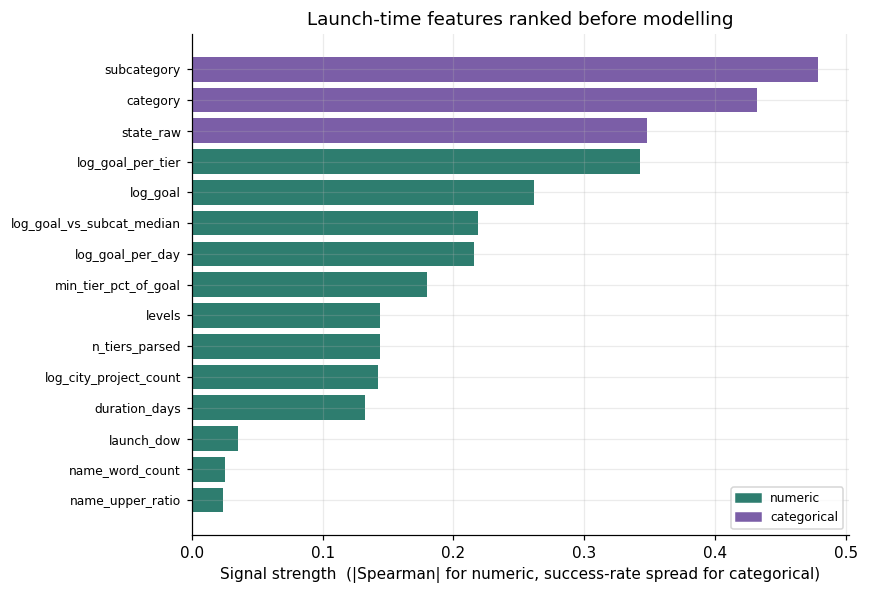

In [25]:
top = signal.head(15).iloc[::-1]
colors = [PLUM if k == "categorical" else TEAL for k in top["kind"]]

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(range(len(top)), top["signal"], color=colors)
ax.set_yticks(range(len(top)))
ax.set_yticklabels(top["feature"], fontsize=8)
ax.set_xlabel("Signal strength  (|Spearman| for numeric, success-rate spread for categorical)")
ax.set_title("Launch-time features ranked before modelling")
handles = [plt.Rectangle((0, 0), 1, 1, color=TEAL),
           plt.Rectangle((0, 0), 1, 1, color=PLUM)]
ax.legend(handles, ["numeric", "categorical"], fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(FIG / "launch_feature_signal.png", dpi=130, bbox_inches="tight")
plt.show()

The two measures are not on a common scale, so read within each colour
rather than across them. What the ranking says:

- **Goal dominates the numeric features**, in raw form and in every derived
  form (`log_goal_per_day`, `log_goal_per_tier`, `log_goal_vs_subcat_median`).
  Those four are all telling a version of the same story and will be
  collinear.
- **Subcategory separates outcomes more than category or state**, which is
  the case for carrying its higher cardinality into modelling.
- **Title features are weak** — length, word count and capitalisation barely
  move the needle. Worth keeping for now since they cost nothing, but they
  are the first candidates to drop in Milestone 3's feature selection.

## 4.8 Correlation structure

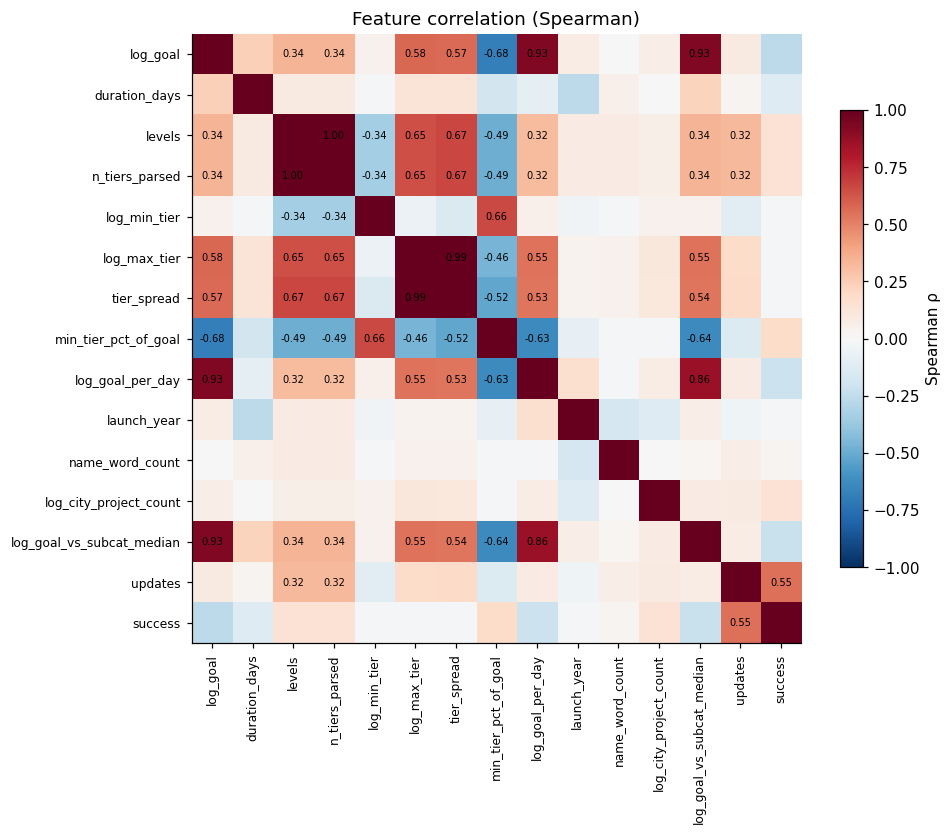

In [26]:
num = ["log_goal", "duration_days", "levels", "n_tiers_parsed", "log_min_tier",
       "log_max_tier", "tier_spread", "min_tier_pct_of_goal", "log_goal_per_day",
       "launch_year", "name_word_count", "log_city_project_count",
       "log_goal_vs_subcat_median", "updates", "success"]
corr = train[num].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(num))); ax.set_xticklabels(num, rotation=90, fontsize=8)
ax.set_yticks(range(len(num))); ax.set_yticklabels(num, fontsize=8)
for i in range(len(num)):
    for j in range(len(num)):
        v = corr.values[i, j]
        if abs(v) > 0.3 and i != j:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5)
ax.grid(False)
plt.colorbar(im, ax=ax, shrink=0.75, label="Spearman ρ")
ax.set_title("Feature correlation (Spearman)")
plt.tight_layout()
plt.savefig(FIG / "correlation_heatmap.png", dpi=130, bbox_inches="tight")
plt.show()

In [27]:
print("Correlation with success, ranked:")
print(corr["success"].drop("success").sort_values(ascending=False).round(4).to_string())

Correlation with success, ranked:
updates                      0.5527
min_tier_pct_of_goal         0.1799
n_tiers_parsed               0.1441
levels                       0.1441
log_city_project_count       0.1420
name_word_count              0.0255
tier_spread                 -0.0092
launch_year                 -0.0105
log_max_tier                -0.0113
log_min_tier                -0.0152
duration_days               -0.1326
log_goal_per_day            -0.2159
log_goal_vs_subcat_median   -0.2189
log_goal                    -0.2612


Two things to carry into Milestone 3:

- **Multicollinearity among the tier features.** `levels`,
  `n_tiers_parsed`, `log_max_tier` and `tier_spread` move together. Trees
  do not care; Logistic Regression coefficients will be unstable. Either
  regularise, or drop `n_tiers_parsed` since it duplicates `levels`.
- **`updates` dwarfs everything else** available in this file, which is the
  whole reason §4.6 exists.

## 4.9 Summary statistics table for the README

In [28]:
summary = pd.DataFrame({
    "successful": train[train.success == 1][["goal", "duration_days", "levels",
                                             "min_tier", "max_tier", "updates"]].median(),
    "failed": train[train.success == 0][["goal", "duration_days", "levels",
                                         "min_tier", "max_tier", "updates"]].median(),
})
summary["ratio"] = (summary["successful"] / summary["failed"]).round(2)
print("Median values by outcome (training split):")
print(summary.round(2).to_string())

Median values by outcome (training split):
               successful  failed  ratio
goal              3000.00  5000.0   0.60
duration_days       30.96    35.0   0.88
levels               8.00     7.0   1.14
min_tier             5.00     5.0   1.00
max_tier          1000.00  1000.0   1.00
updates              5.00     0.0    inf


In [29]:
summary.to_csv("../reports/summary_by_outcome.csv")
signal.to_csv("../reports/feature_signal_ranking.csv", index=False)
pd.concat([
    cat_tbl.assign(dimension="category"),
    dur_tbl.assign(dimension="duration"),
    upd_tbl.assign(dimension="updates"),
    tier_tbl.assign(dimension="reward_tiers"),
]).to_csv("../reports/eda_success_rates.csv")
print("Wrote 3 CSVs to ../reports/ and "
      f"{len(list(FIG.glob('*.png')))} figures to ../reports/figures/")

Wrote 3 CSVs to ../reports/ and 37 figures to ../reports/figures/


## Findings — Tasks 4 & 5

### Factors ranked by strength

| Rank | Factor | Effect | Available at launch? |
|---|---|---|---|
| 1 | **Updates** | 20% → 92% success from 0 to 13+ updates | ❌ **No** |
| 2 | **Goal** | Monotonic decline across all 10 deciles | ✅ Yes |
| 3 | **Subcategory** | Widest categorical spread | ✅ Yes |
| 4 | **Reward tiers** | More tiers help, within every goal size (the entry-price gap is mostly a tier-count effect) | ✅ Yes |
| 5 | **Duration** | Longer is *worse*; exactly-30-day (default) campaigns are a dip | ✅ Yes |
| 6 | **Category** | Real effect that survives controlling for goal | ✅ Yes |
| 7 | **Location** | Large — ~27 points between best and worst states; city size matters too | ✅ Yes |

*Rows 4, 5 and 7 were corrected in Milestone 4 after re-testing; the
original wording is recorded in notebook 10, §11.6.*

### Recommendations for Milestone 3

1. **Exclude `updates` from the primary feature set.** It is the strongest
   signal in the data and also unavailable at launch, with causation running
   at least partly backwards. Record the decision in a leakage register
   before training anything. A second, clearly-labelled mid-campaign model
   could legitimately use it for triaging live campaigns.
2. **Exclude the outcome columns outright** — `pledged`, `backers`,
   `funded_percentage`, `comments`. `funded_percentage` mechanically
   determines the target.
3. **Use `log_goal`, not `goal`.** Five orders of magnitude of right skew.
4. **Expect collinearity** among the goal-derived features and among the
   reward-tier features. Trees will cope; Logistic Regression coefficients
   will not be stable without regularisation.
5. **Consider a chronological split** alongside the random one. `launch_date`
   was recovered in Milestone 1, and training on earlier campaigns to test on
   later ones matches the deployment scenario.
6. **Rank features with permutation importance or SHAP**, not Gini
   importance, which is biased toward continuous and high-cardinality
   features.

### Confounds and caveats

1. **Category vs goal** — cheap categories ask for less and succeed more.
   Controlled for in §4.2 by comparing within goal quartiles; both effects
   are real.
2. **Random split, not chronological.** See recommendation 5.
3. **Platform drift.** The data spans 2009–2012 of a changing Kickstarter,
   including the June 2011 duration cap. `launch_year` partly absorbs this.
4. **The published 80.2% / F1 0.834 benchmark was produced with `updates`
   included.** Our pre-launch results will not be directly comparable, and
   the comparison belongs in Milestone 3.